# Phase 8 : tableau de bord (Q7)

Ce notebook prépare les données du tableau de bord, dessine les maquettes et vérifie chaque chiffre affiché. Le tableau de bord lui-même est une application Streamlit : `dashboard/app.py`. Pour l'ouvrir, depuis la racine du dépôt :

```bash
streamlit run dashboard/app.py
```

Les fonctions sont dans `src/dashboard_data.py` (préparation) et `dashboard/calculs.py` (chiffres affichés). Chaque étape est expliquée dans `docs/`.

## P8-01 : utilisateurs et indicateurs clés

Trois utilisateurs : l'analyste de la fraude (revue quotidienne de la liste priorisée), le responsable de la fraude (charge de travail, seuil, évolution) et l'équipe relation client ou marketing (profils de clients). La liste des indicateurs clés, avec la question à laquelle chacun répond, est dans `docs/P8-01_utilisateurs_indicateurs.md`.

Critère de fin : liste des indicateurs clés validée.

## P8-02 : outil et maquettes

Outil retenu : Streamlit (Python, gratuit, lit directement les fichiers Parquet du projet, filtres simples à coder). Une maquette par page, avec les couleurs de la charte (`src/charte.py`). Comparaison des outils dans `docs/P8-02_outil_maquette.md`.

Critère de fin : maquette validée par l'équipe.

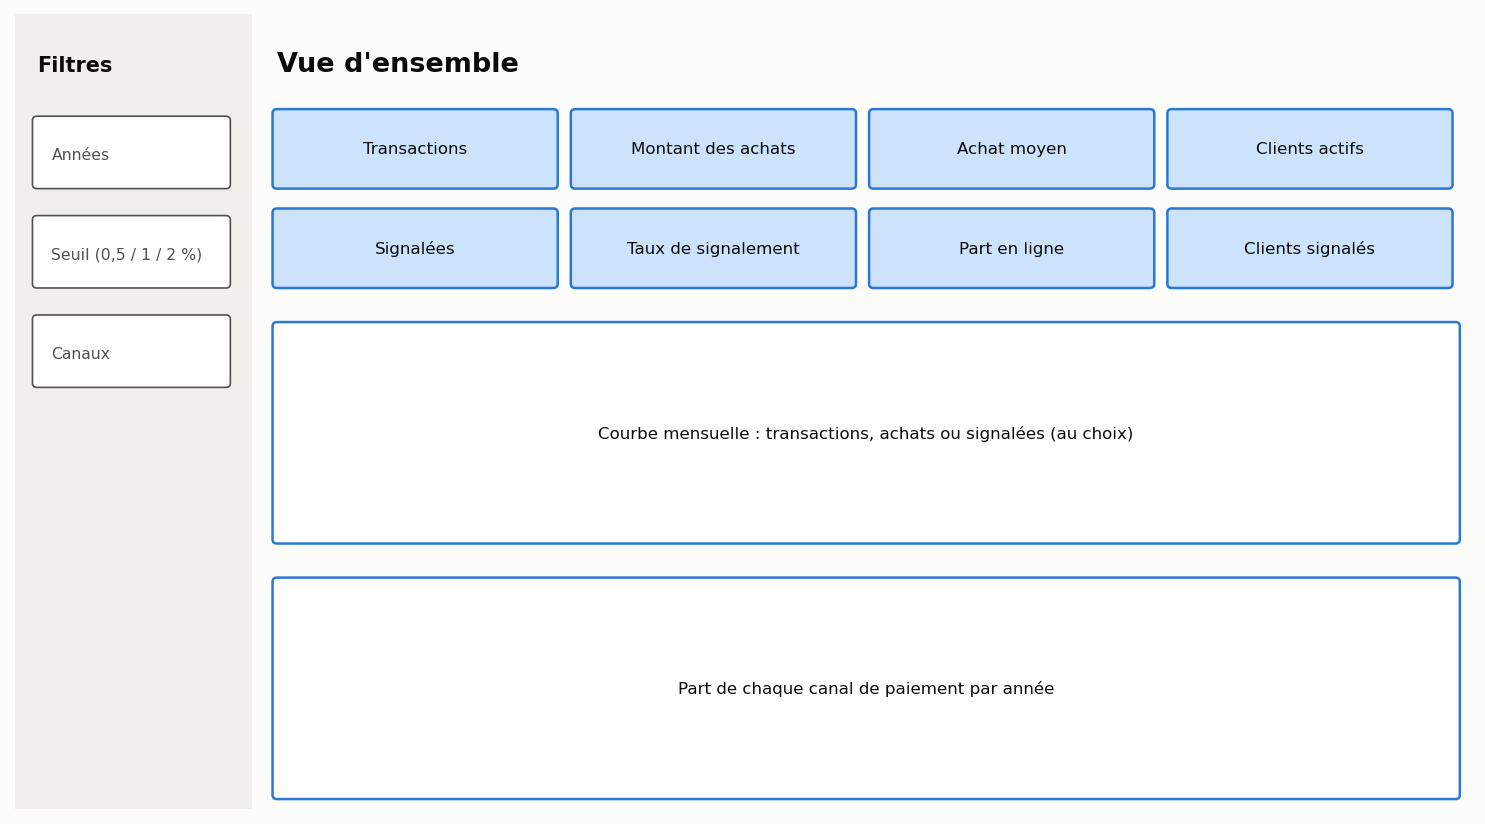

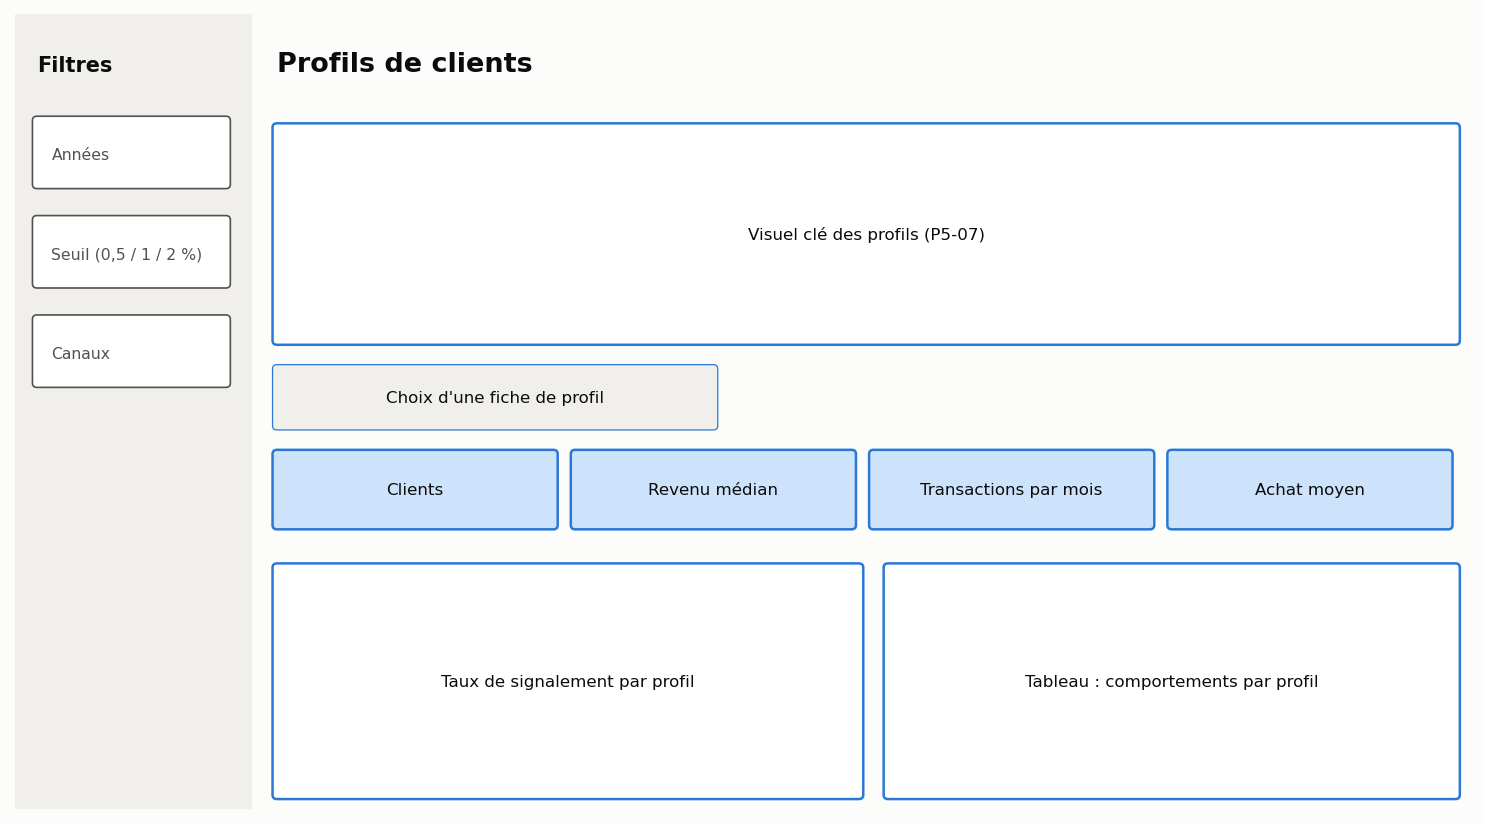

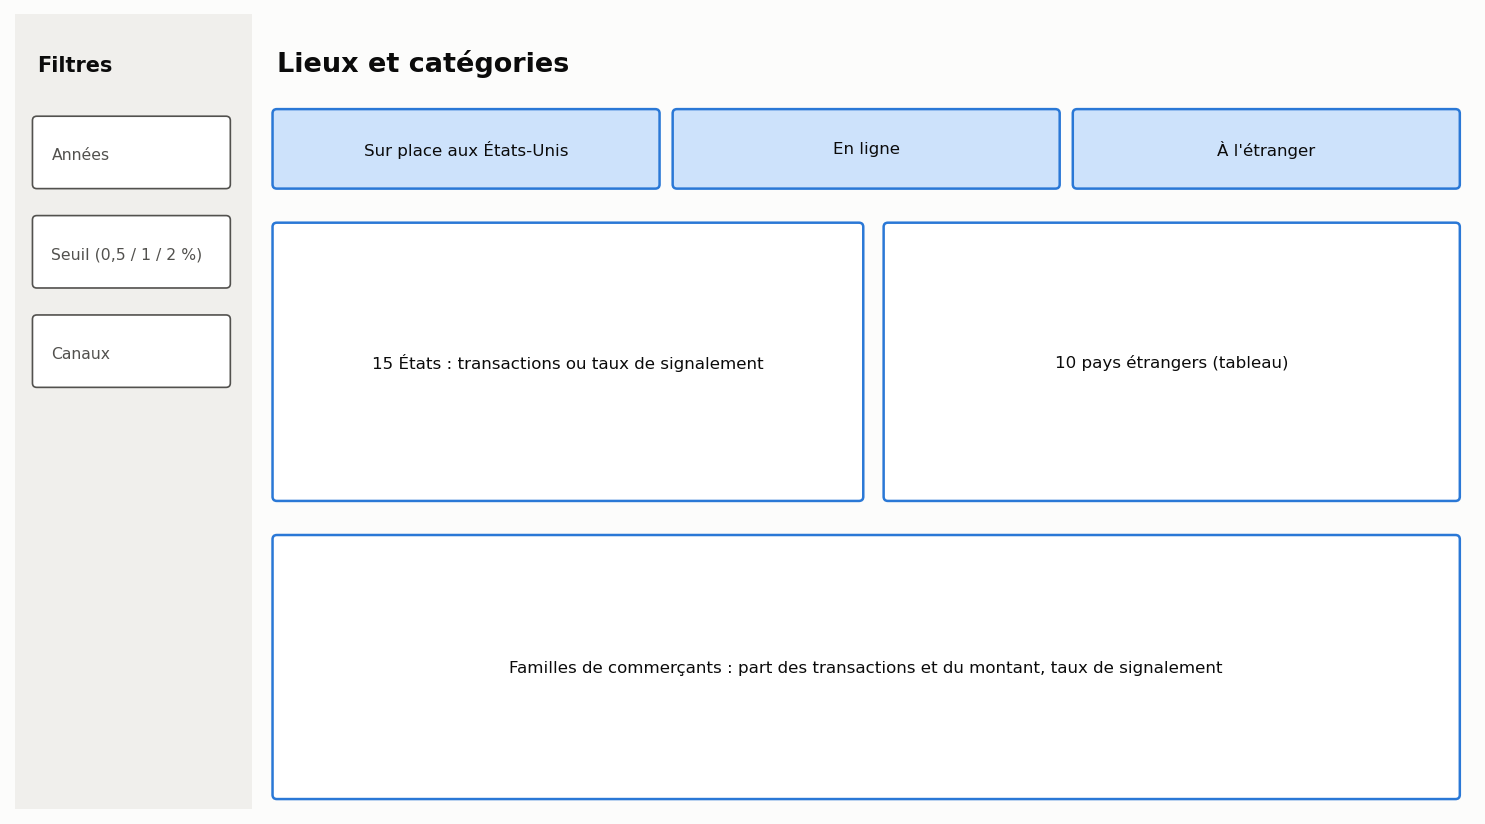

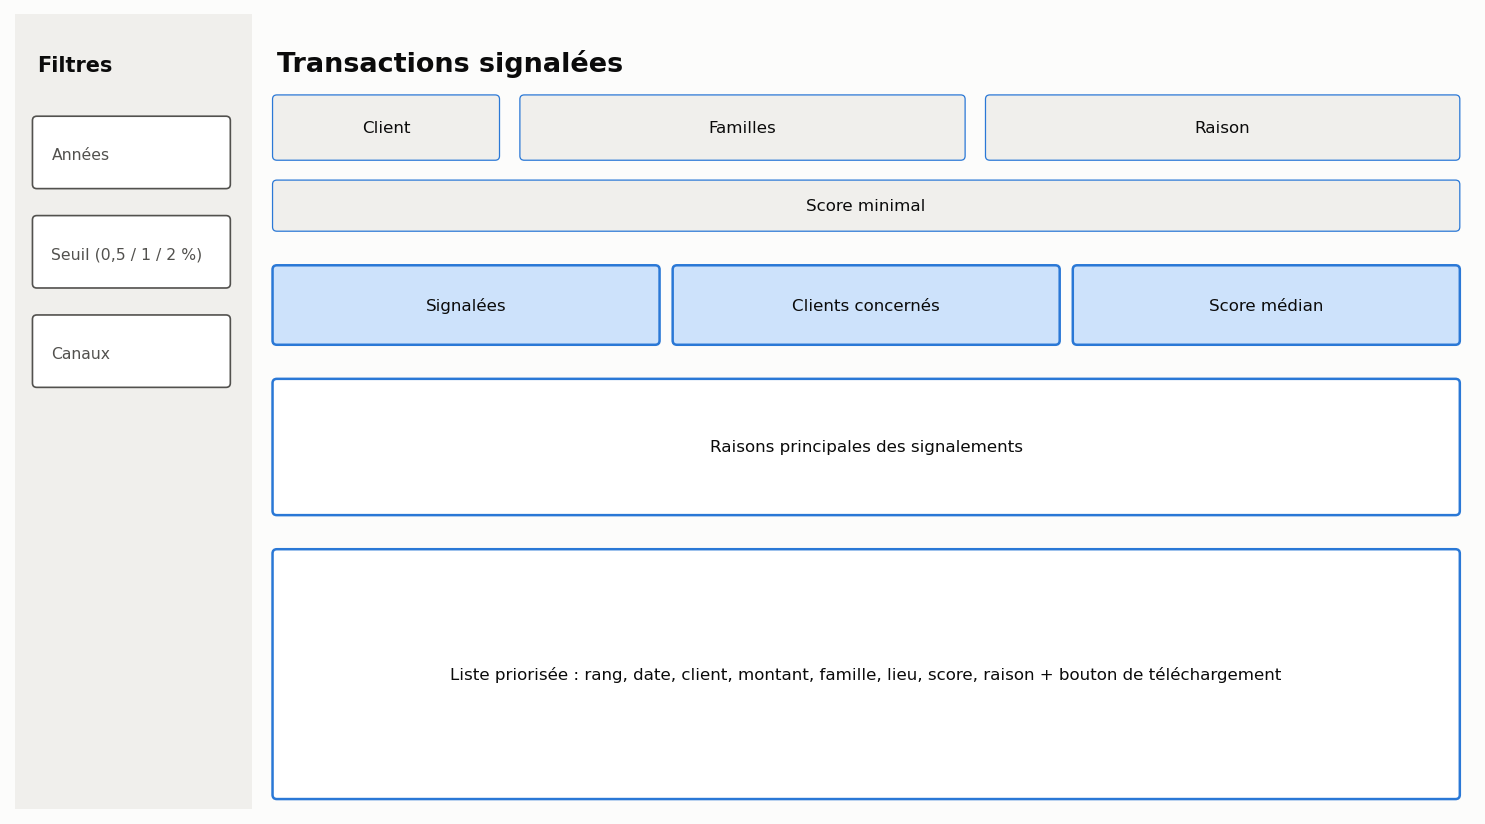

In [1]:
import time
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyBboxPatch
from IPython.display import Image, display

from src.load_data import load_clean_table
from src.charte import apply_style, save_figure, BLUE, BLUE_RAMP, TEXT_SECONDARY, SURFACE
from src.dashboard_data import DASHBOARD_INPUT_COLUMNS, prepare_base, build_dashboard_tables, save_dashboard_tables
from src.detection import precision_recall_fixed_threshold

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

def maquette(titre, blocs, nom):
    fig, ax = plt.subplots(figsize=(10, 5.6))
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 56)
    ax.axis("off")
    ax.add_patch(FancyBboxPatch((0, 0), 16, 56, boxstyle="square", facecolor="#f0efec", edgecolor="none"))
    ax.text(1.5, 52, "Filtres", fontsize=10, fontweight="bold")
    for i, f in enumerate(["Années", "Seuil (0,5 / 1 / 2 %)", "Canaux"]):
        ax.add_patch(FancyBboxPatch((1.5, 44 - 7 * i), 13, 4.5, boxstyle="round,pad=0.3", facecolor="white",
                                    edgecolor=TEXT_SECONDARY, linewidth=0.8))
        ax.text(2.5, 45.8 - 7 * i, f, fontsize=7.5, color=TEXT_SECONDARY)
    ax.text(18, 52, titre, fontsize=13, fontweight="bold")
    for x, y, w, h, texte, genre in blocs:
        couleur = {"chiffre": BLUE_RAMP[0], "graphique": "white", "tableau": "white", "filtre": "#f0efec"}[genre]
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.3", facecolor=couleur, edgecolor=BLUE,
                                    linewidth=1.2 if genre != "filtre" else 0.6))
        ax.text(x + w / 2, y + h / 2, texte, ha="center", va="center", fontsize=8, wrap=True)
    fig.tight_layout()
    save_figure(fig, nom)
    plt.close(fig)

tuiles = lambda y, noms: [(18 + 20.5 * i, y, 19, 5, n, "chiffre") for i, n in enumerate(noms)]
maquette("Vue d'ensemble",
         tuiles(44, ["Transactions", "Montant des achats", "Achat moyen", "Clients actifs"])
         + tuiles(37, ["Signalées", "Taux de signalement", "Part en ligne", "Clients signalés"])
         + [(18, 19, 81, 15, "Courbe mensuelle : transactions, achats ou signalées (au choix)", "graphique"),
            (18, 1, 81, 15, "Part de chaque canal de paiement par année", "graphique")],
         "P8-02_maquette_vue_ensemble")
maquette("Profils de clients",
         [(18, 33, 81, 15, "Visuel clé des profils (P5-07)", "graphique"),
          (18, 27, 30, 4, "Choix d'une fiche de profil", "filtre")]
         + [(18 + 20.5 * i, 20, 19, 5, n, "chiffre") for i, n in enumerate(["Clients", "Revenu médian",
                                                                             "Transactions par mois", "Achat moyen"])]
         + [(18, 1, 40, 16, "Taux de signalement par profil", "graphique"),
            (60, 1, 39, 16, "Tableau : comportements par profil", "tableau")],
         "P8-02_maquette_profils")
maquette("Lieux et catégories",
         [(18 + 27.5 * i, 44, 26, 5, n, "chiffre") for i, n in enumerate(["Sur place aux États-Unis", "En ligne",
                                                                          "À l'étranger"])]
         + [(18, 22, 40, 19, "15 États : transactions ou taux de signalement", "graphique"),
            (60, 22, 39, 19, "10 pays étrangers (tableau)", "tableau"),
            (18, 1, 81, 18, "Familles de commerçants : part des transactions et du montant, taux de signalement", "graphique")],
         "P8-02_maquette_lieux_categories")
maquette("Transactions signalées",
         [(18, 46, 15, 4, "Client", "filtre"), (35, 46, 30, 4, "Familles", "filtre"), (67, 46, 32, 4, "Raison", "filtre"),
          (18, 41, 81, 3, "Score minimal", "filtre")]
         + [(18 + 27.5 * i, 33, 26, 5, n, "chiffre") for i, n in enumerate(["Signalées", "Clients concernés",
                                                                            "Score médian"])]
         + [(18, 21, 81, 9, "Raisons principales des signalements", "graphique"),
            (18, 1, 81, 17, "Liste priorisée : rang, date, client, montant, famille, lieu, score, raison "
             "+ bouton de téléchargement", "tableau")],
         "P8-02_maquette_transactions_signalees")
for nom in ["vue_ensemble", "profils", "lieux_categories", "transactions_signalees"]:
    display(Image(f"docs/figures/P8-02_maquette_{nom}.png", width=600))

**Constats**

- Les quatre maquettes sont dessinées, une par page, avec les couleurs de la charte : `docs/figures/P8-02_maquette_*.png`.
- Chaque page commence par des chiffres clés, puis un ou deux graphiques, puis un tableau. Les filtres communs sont dans la barre de gauche.
- Il reste à faire valider les maquettes par l'équipe.

## P8-03 : préparer les données du tableau de bord

Tables résumées par jour, mois, catégorie, État, pays et profil, table des transactions signalées (seuil 2 %, avec les colonnes des seuils 0,5 % et 1 %), fiches des profils et précision du score par seuil (P7-11). Elles sont enregistrées dans `data/dashboard/` (non versionné).

Critère de fin : tables exportées, de taille raisonnable. Voir `docs/P8-03_donnees_tableau_bord.md`.

In [2]:
df = load_clean_table("analysis", columns=DASHBOARD_INPUT_COLUMNS + ["is_fraud"])
scores = load_clean_table("risk_scores", columns=["id", "risk_score", "anomaly_pct", "flag_0_5", "flag_1",
                                                  "flag_2", "main_reason"])
profils = load_clean_table("client_profiles", columns=["client_id", "profil_nom"])
fiches = load_clean_table("profile_sheets")

debut = time.perf_counter()
base = prepare_base(df, scores, profils)
tables = build_dashboard_tables(base, profils, fiches)

etiquetees = base["is_fraud"].notna().to_numpy()
y = base.loc[etiquetees, "is_fraud"].astype(int).to_numpy()
evaluation = []
for seuil, col in [("0,5 %", "flag_0_5"), ("1 %", "flag_1"), ("2 %", "flag_2")]:
    e = precision_recall_fixed_threshold(y, base.loc[etiquetees, col].to_numpy())
    evaluation.append({"seuil": seuil, "precision": e["précision_%"], "rappel": e["rappel_%"]})
tables["evaluation"] = pd.DataFrame(evaluation)
tailles = save_dashboard_tables(tables)
print(f"Préparation : {time.perf_counter() - debut:.0f} s ; taille totale : {tailles['taille (Mo)'].sum():.1f} Mo")
tailles

Préparation : 23 s ; taille totale : 8.8 Mo


,lignes,colonnes,taille (Mo)
table,,,
jours,3591,10,0.10
mois,528,13,0.03
familles,332,12,0.02
etats,512,11,0.02
pays,671,11,0.02
profils_annees,50,11,0.01
clients_annees,11903,6,0.08
profils,4,7,0.01
signalees,266128,16,8.55


**Constats**

- Dix tables sont exportées dans `data/dashboard/`, pour 8,8 Mo au total. La préparation prend 23 s.
- La plus grande est la table des transactions signalées : 266 128 lignes (seuil 2 %) pour 8,55 Mo. Toutes les autres font 0,10 Mo ou moins.
- Les tables résumées sont petites : 3 591 jours, 528 lignes par mois, canal et lieu, 332 lignes par année, famille et lieu, 512 lignes par année et État.
- Le tableau de bord ne lit donc jamais les 13 millions de transactions : il s'ouvre vite. Le critère de fin est validé.

## P8-04 à P8-07 : les quatre pages

| Ticket | Page | Contenu |
| --- | --- | --- |
| P8-04 | Vue d'ensemble | Chiffres clés, courbe mensuelle, canaux de paiement par année |
| P8-05 | Profils de clients | Visuel des profils, fiche de chaque profil, signalements par profil |
| P8-06 | Lieux et catégories | En ligne, sur place, à l'étranger ; États ; pays ; familles de commerçants |
| P8-07 | Transactions signalées | Liste priorisée, filtres (client, famille, raison, score), raisons, téléchargement |

Les filtres communs (années, seuil, canaux) sont dans la barre de gauche. Chaque page est testée ci-dessous : elle s'affiche sans erreur avec les filtres par défaut. Les captures d'écran sont dans `docs/figures/P8-0*_page_*.png`.

Critère de fin de chaque ticket : page terminée. Voir `docs/P8-04_page_vue_ensemble.md` à `docs/P8-07_page_transactions_signalees.md`.

In [3]:
import streamlit.logger
from streamlit import config
from streamlit.testing.v1 import AppTest

# Messages techniques de Streamlit masqués : ils ne concernent pas les chiffres
config.set_option("logger.level", "error")
streamlit.logger.set_log_level("error")

def executer_page(nom_page, annees, seuil, canaux):
    import sys
    from pathlib import Path
    sys.path.insert(0, str(Path.cwd()))
    from dashboard import pages
    from dashboard.calculs import charger
    getattr(pages, nom_page)(charger(), {"annees": annees, "seuil": seuil, "canaux": canaux})

CANAUX = ["Bande magnétique", "Puce", "En ligne"]
essais = []
for nom_page in ["vue_ensemble", "profils", "lieux_categories", "transactions_signalees"]:
    at = AppTest.from_function(executer_page, args=(nom_page, (2010, 2019), "1 %", CANAUX), default_timeout=120)
    at.run()
    essais.append({"page": nom_page, "erreurs": len(at.exception), "chiffres affichés": len(at.metric),
                   "graphiques et tableaux": len(at.get("vega_lite_chart")) + len(at.get("arrow_vega_lite_chart")) + len(at.dataframe)})
print("Toutes les pages s'affichent sans erreur :", all(e["erreurs"] == 0 for e in essais))
pd.DataFrame(essais)

Toutes les pages s'affichent sans erreur : True


,page,erreurs,chiffres affichés,graphiques et tableaux
0,vue_ensemble,0,8,2
1,profils,0,4,2
2,lieux_categories,0,3,4
3,transactions_signalees,0,3,2


**Constats**

- Les quatre pages s'affichent sans erreur avec les filtres par défaut.
- La page « Vue d'ensemble » montre 8 chiffres clés et 2 graphiques. La page « Profils de clients » montre 4 chiffres et 2 éléments (visuel, graphique et tableau). La page « Lieux et catégories » montre 3 chiffres et 4 graphiques ou tableaux. La page « Transactions signalées » montre 3 chiffres, le graphique des raisons et la liste.
- Les captures d'écran sont dans `docs/figures/P8-04_page_vue_ensemble.png` à `P8-07_page_transactions_signalees.png`.

## P8-08 : vérifier les chiffres du tableau de bord

Chaque chiffre affiché est recalculé directement depuis la table d'analyse et les scores (sans passer par les tables du tableau de bord), puis comparé. Les filtres sont vérifiés avec plusieurs combinaisons : toute la période, une seule année, un seul canal, chaque seuil. Enfin, les chiffres réellement affichés par la page « Vue d'ensemble » sont lus dans l'application.

Critère de fin : aucun écart constaté. Voir `docs/P8-08_verification_chiffres.md`.

In [4]:
sys.path.insert(0, ".")
from dashboard.calculs import charger, indicateurs, resume_familles, classement, liste_signalee, resume_profils

t = charger()
COL = {"0,5 %": "flag_0_5", "1 %": "flag_1", "2 %": "flag_2"}
controles = []

def comparer(nom, affiche, attendu, tolerance=1e-6):
    ecart = abs(float(affiche) - float(attendu))
    controles.append({"contrôle": nom, "tableau de bord": affiche, "calcul direct": attendu,
                      "écart": ecart, "statut": ecart <= tolerance * max(1, abs(float(attendu)))})

combinaisons = [((2010, 2019), "1 %", CANAUX), ((2015, 2015), "0,5 %", CANAUX), ((2010, 2019), "2 %", ["En ligne"]),
                ((2012, 2018), "1 %", ["Puce", "Bande magnétique"])]
for annees, seuil, canaux in combinaisons:
    k = indicateurs(t, annees, canaux, seuil)
    sel = base["year"].between(*annees) & base["canal"].isin(canaux)
    sel_annees = base["year"].between(*annees)
    etiquette = f"{annees[0]}-{annees[1]}, {seuil}, {'/'.join(canaux)}"
    comparer(f"transactions ({etiquette})", k["transactions"], sel.sum())
    comparer(f"montant des achats ({etiquette})", k["achats"], base.loc[sel, "achat"].sum())
    comparer(f"signalées ({etiquette})", k["signalees"], base.loc[sel, COL[seuil]].sum())
    comparer(f"part en ligne ({etiquette})", k["part_en_ligne"], 100 * base.loc[sel, "is_online"].mean())
    comparer(f"clients actifs ({etiquette})", k["clients_actifs"], base.loc[sel_annees, "client_id"].nunique())
    comparer(f"clients signalés ({etiquette})", k["clients_signales"],
             base.loc[sel_annees & (base[COL[seuil]] == 1), "client_id"].nunique())

fam = resume_familles(t, (2010, 2019), ["Sur place aux États-Unis", "En ligne", "À l'étranger"], "1 %").set_index("mcc_family")
direct = base.groupby("mcc_family", observed=True).agg(n=("id", "size"), s=("flag_1", "sum"))
for famille in direct.index:
    comparer(f"famille {famille} : transactions", fam.loc[famille, "transactions"], direct.loc[famille, "n"])
    comparer(f"famille {famille} : signalées", fam.loc[famille, "signalees"], direct.loc[famille, "s"])

etats = classement(t, "etats", "merchant_state_clean", (2010, 2019), "1 %", n=5).set_index("merchant_state_clean")
sur_place = base[base["lieu"] == "Sur place aux États-Unis"]
for etat in etats.index:
    comparer(f"État {etat} : transactions", etats.loc[etat, "transactions"], (sur_place["merchant_state_clean"] == etat).sum())

prof = resume_profils(t, (2010, 2019), "1 %").set_index("profil_nom")
for profil in prof.index:
    comparer(f"profil {profil} : signalées", prof.loc[profil, "signalees"],
             base.loc[base["profil_nom"] == profil, "flag_1"].sum())

for seuil in ["0,5 %", "1 %", "2 %"]:
    comparer(f"liste des signalées, seuil {seuil}", len(liste_signalee(t, (2010, 2019), seuil)), base[COL[seuil]].sum())
client_test = int(base.loc[base["flag_1"] == 1, "client_id"].value_counts().index[0])
dix = liste_signalee(t, (2010, 2019), "1 %", client=client_test).head(10)
attendu = base[(base["client_id"] == client_test) & (base["flag_1"] == 1)].nlargest(10, "risk_score")
comparer(f"10 transactions les plus risquées du client {client_test} (mêmes identifiants)",
         int(set(dix["id"]) == set(attendu["id"])), 1)

verif = pd.DataFrame(controles)
print(f"Contrôles : {len(verif)} ; écarts constatés : {int((~verif['statut']).sum())}")
print("Critère de fin validé :", verif["statut"].all())
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)
verif

Contrôles : 62 ; écarts constatés : 0
Critère de fin validé : True


,contrôle,tableau de bord,calcul direct,écart,statut
0,"transactions (2010-2019, 1 %, Bande magnétique...","13,305,915.00","13,305,915.00",0.00,True
1,"montant des achats (2010-2019, 1 %, Bande magn...","639,354,564.62","639,354,564.62",0.00,True
2,"signalées (2010-2019, 1 %, Bande magnétique/Pu...","133,075.00","133,075.00",0.00,True
3,"part en ligne (2010-2019, 1 %, Bande magnétiqu...",11.75,11.75,0.00,True
4,"clients actifs (2010-2019, 1 %, Bande magnétiq...","1,219.00","1,219.00",0.00,True
5,"clients signalés (2010-2019, 1 %, Bande magnét...","1,219.00","1,219.00",0.00,True
6,"transactions (2015-2015, 0,5 %, Bande magnétiq...","1,388,065.00","1,388,065.00",0.00,True
7,"montant des achats (2015-2015, 0,5 %, Bande ma...","66,503,695.18","66,503,695.18",0.00,True
8,"signalées (2015-2015, 0,5 %, Bande magnétique/...","5,860.00","5,860.00",0.00,True
9,"part en ligne (2015-2015, 0,5 %, Bande magnéti...",12.33,12.33,0.00,True


In [5]:
# Chiffres lus dans l'application elle-même (page « Vue d'ensemble », filtres par défaut)
at = AppTest.from_function(executer_page, args=("vue_ensemble", (2010, 2019), "1 %", CANAUX), default_timeout=120)
at.run()
lus = {m.label: m.value for m in at.metric}
attendus = {
    "Transactions": f"{len(base):,}".replace(",", " "),
    "Transactions signalées": f"{int(base['flag_1'].sum()):,}".replace(",", " "),
    "Clients actifs": f"{base['client_id'].nunique():,}".replace(",", " "),
}
lecture = pd.DataFrame([{"chiffre": k, "affiché": lus.get(k), "attendu": v, "identique": lus.get(k) == v}
                        for k, v in attendus.items()])
print("Chiffres affichés identiques :", lecture["identique"].all())
lecture

Chiffres affichés identiques : True


,chiffre,affiché,attendu,identique
0,Transactions,13 305 915,13 305 915,True
1,Transactions signalées,133 075,133 075,True
2,Clients actifs,1 219,1 219,True


**Constats**

- 62 chiffres du tableau de bord sont comparés au calcul direct : aucun écart. Le critère de fin est validé.
- Les filtres sont vérifiés avec quatre combinaisons : toute la période au seuil de 1 %, l'année 2015 au seuil de 0,5 %, le canal en ligne au seuil de 2 %, et puce et bande magnétique de 2012 à 2018.
- La liste des 10 transactions les plus risquées d'un client contient exactement les mêmes transactions que le calcul direct.
- Les chiffres réellement affichés par l'application sont identiques aux attendus : 13 305 915 transactions, 133 075 transactions signalées et 1 219 clients actifs.